# Task 4 — Random Forests & Ensembles: bagging, voting, stacking and AdaBoost on a spam filter

MOP 3231 · Machine Learning (Python) · Abror Imamsidikov

Data: UCI Spambase (Hopkins, Reeber, Forman & Suermondt, 1999; CC BY 4.0; doi:10.24432/C53G6X), deduplicated by the
instructor: 4204 e-mails, 57 numeric features, label `spam` (1 = spam, 0 = legitimate mail). Spam is the positive class;
a false positive is a legitimate mail flagged as spam.

## Part 0 — Setup

In [1]:
import sys

import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)

3.12.12 2.3.4 2.3.3 1.7.2 3.10.7


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 2954          # last 4 digits of your student ID, as an integer (0421 -> 421)
data = pd.read_csv("data/spambase.csv")
feature_names = [c for c in data.columns if c != "spam"]
X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)

(4204, 57) 39.9 (3153, 57) (1051, 57)


**SEED = 2954** (the last four digits of my student ID). It seeds the train/test split, the folds `cv` and every
random model below. The check line prints `(4204, 57) 39.9 (3153, 57) (1051, 57)` as the handout requires.

### The fixed models (exactly as given in the handout)

In [3]:
import math

import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]   # members of voting and stacking in Parts 3-4

In [4]:
from sklearn.model_selection import cross_validate

n_train, n_test = len(y_train), len(y_test)


def cv_scores(model):
    """Accuracy on each of the five folds of cv on the training split."""
    return cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)["test_score"]


def fold_table(scores):
    """Table: one row per model, the five fold scores, mean and std (ddof=0)."""
    t = pd.DataFrame(scores).T
    t.columns = [f"fold {i + 1}" for i in range(t.shape[1])]
    t["mean"] = t.iloc[:, :5].mean(axis=1)
    t["std"] = t.iloc[:, :5].std(axis=1, ddof=0)
    return t


def paired(a, b):
    """Paired differences a - b (per fold or per draw) with mean, std and the 'inside the spread' verdict."""
    d = np.asarray(a) - np.asarray(b)
    row = {f"#{i + 1}": v for i, v in enumerate(d)}
    row["mean"], row["std"] = d.mean(), d.std()
    row["inside spread"] = bool(abs(d.mean()) <= d.std())
    return row

`cv_scores` is the handout's `cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]`
(with `n_jobs=-1` only for speed; it clones the model and uses the same folds). `paired` returns the paired
differences, their mean and std (`np.std`, ddof=0), and whether the difference is **inside the fold spread**
(|mean| ≤ std), in which case no winner may be named.

## Part 1 — Bagging and out-of-bag estimates

In [5]:
def oob_mask(sample_indices, n_samples):
    """Boolean mask of the rows that do NOT occur in sample_indices.

    sample_indices: list or 1-D integer array of row numbers in [0, n_samples - 1], repeats allowed, may be empty.
    Returns a new bool array of shape (n_samples,); element i is True exactly when i is not in sample_indices.
    """
    idx = np.asarray(sample_indices, dtype=np.int64).reshape(-1)   # a new array; the argument is not touched
    mask = np.ones(int(n_samples), dtype=bool)
    mask[idx] = False
    return mask

In [6]:
# the examples of the handout are part of the rules
assert oob_mask([0, 2, 2], 5).tolist() == [False, True, False, True, True]
assert oob_mask([], 3).tolist() == [True, True, True]
assert oob_mask(np.array([3, 0]), 4).tolist() == [False, True, True, False]
_a = np.array([3, 0]); oob_mask(_a, 4); assert _a.tolist() == [3, 0]          # argument unchanged
assert oob_mask([1], 2).dtype == bool and oob_mask([1], 2).shape == (2,)
print("oob_mask: all examples pass")

oob_mask: all examples pass


### 1.1 Out-of-bag share

In [7]:
bag.fit(X_train, y_train)
n = n_train
oob_share = np.array([oob_mask(s, n).mean() for s in bag.estimators_samples_])
print(f"n = {n} training rows, {len(bag.estimators_)} trees")
print(f"mean out-of-bag share per tree : {oob_share.mean():.4f}   formula (1 - 1/n)^n     = {(1 - 1 / n) ** n:.4f}")
print(f"mean in-bag share per tree     : {1 - oob_share.mean():.4f}   formula 1 - (1 - 1/n)^n = {1 - (1 - 1 / n) ** n:.4f}")
print(f"(range over the 100 trees: {oob_share.min():.4f} to {oob_share.max():.4f})")

n = 3153 training rows, 100 trees
mean out-of-bag share per tree : 0.3685   formula (1 - 1/n)^n     = 0.3678
mean in-bag share per tree     : 0.6315   formula 1 - (1 - 1/n)^n = 0.6322
(range over the 100 trees: 0.3543 to 0.3825)


### 1.2 Out-of-bag accuracy by hand

In [8]:
votes = np.zeros((n, 2))
for est, sample in zip(bag.estimators_, bag.estimators_samples_):
    m = oob_mask(sample, n)
    pred = est.predict(X_train[m]).astype(int)
    np.add.at(votes, (np.flatnonzero(m), pred), 1)       # one vote per tree for which the row is out of bag
oob_pred = np.argmax(votes, axis=1)                         # tie -> class 0
my_oob_acc = np.mean(oob_pred == y_train)
print(f"rows with no out-of-bag vote: {(votes.sum(axis=1) == 0).sum()}")
print(f"my out-of-bag accuracy = {my_oob_acc:.6f}")
print(f"bag.oob_score_         = {bag.oob_score_:.6f}")
print("equal:", my_oob_acc == bag.oob_score_)

rows with no out-of-bag vote: 0
my out-of-bag accuracy = 0.941326
bag.oob_score_         = 0.941326
equal: True


### 1.3 Five models on the same folds

In [9]:
scores = {name: cv_scores(m) for name, m in
          [("tree", tree), ("bag", bag), ("rf", rf), ("lr", lr), ("bag_lr", bag_lr)]}
fold_table(scores).round(4)

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
tree,0.9017,0.8970,0.9255,0.8968,0.8968,0.9036,0.0111
bag,0.9255,0.9303,0.9556,0.9333,0.9333,0.9356,0.0104
rf,0.9477,0.9366,0.9635,0.9429,0.9349,0.9451,0.0103
lr,0.9113,0.9255,0.9540,0.9286,0.9444,0.9328,0.0150
bag_lr,0.9113,0.9271,0.9525,0.9317,0.9476,0.9340,0.0148


In [10]:
pd.DataFrame({"bag - tree": paired(scores["bag"], scores["tree"]),
              "rf - tree": paired(scores["rf"], scores["tree"]),
              "bag_lr - lr": paired(scores["bag_lr"], scores["lr"])}).T.round(4)

,#1,#2,#3,#4,#5,mean,std,inside spread
bag - tree,0.023772,0.033281,0.030111,0.036508,0.036508,0.032036,0.004765,False
rf - tree,0.045959,0.03962,0.038035,0.046032,0.038095,0.041548,0.003675,False
bag_lr - lr,0.0,0.001585,-0.001585,0.003175,0.003175,0.00127,0.00185,True


### 1.4 One forest, three estimates

In [11]:
rf.fit(X_train, y_train)            # fitted once and kept for Part 2
p_rf = rf.score(X_test, y_test)
se_rf = math.sqrt(p_rf * (1 - p_rf) / n_test)
rf_cv_mean, rf_cv_std = scores["rf"].mean(), scores["rf"].std()
print(f"oob_score_          : {rf.oob_score_:.4f}")
print(f"CV mean (5 folds)   : {rf_cv_mean:.4f}  (fold std {rf_cv_std:.4f})")
print(f"test accuracy p     : {p_rf:.4f}  ± SE {se_rf:.4f}   (n_test = {n_test})")
print(f"|oob - CV mean| = {abs(rf.oob_score_ - rf_cv_mean):.4f}  <= fold std {rf_cv_std:.4f}: "
      f"{abs(rf.oob_score_ - rf_cv_mean) <= rf_cv_std}")

oob_score_          : 0.9477
CV mean (5 folds)   : 0.9451  (fold std 0.0103)
test accuracy p     : 0.9458  ± SE 0.0070   (n_test = 1051)
|oob - CV mean| = 0.0025  <= fold std 0.0103: True


### Part 1 — answers

**Out-of-bag share.** The mean out-of-bag share per tree is 0.3685, against the formula (1 − 1/n)^n = 0.3678 for
n = 3153; the in-bag share is 0.6315 against 1 − (1 − 1/n)^n = 0.6322. They differ in the fourth decimal: about 37 %
of the training rows are left out of each bootstrap sample, as the formula says (it is close to 1/e ≈ 0.368).
My hand-made out-of-bag accuracy is 0.941326, exactly equal to `bag.oob_score_`.

**(a) Did bagging help?**
*Tree.* Bagging raised the CV accuracy from 0.9036 to 0.9356. The paired differences bag − tree are positive on all
five folds (0.024 to 0.037), mean +0.0320 with std 0.0048, so the gain is far outside the fold spread: bagging helps
the tree. The forest helps even more (rf − tree: mean +0.0415, std 0.0037, positive on every fold).
*Logistic regression.* bag_lr − lr has mean +0.0013 with std 0.0019 (fold differences between −0.0016 and +0.0032).
The mean is inside the fold spread, so my data cannot separate bagged and plain logistic regression.
*Mechanism.* Bagging averages models fitted on bootstrap samples, and an average of models only removes the
**variance** part of the error. A fully grown tree has high variance: a few changed rows change its splits and its
leaves, so 100 bootstrap trees make different mistakes and the majority vote cancels many of them. The random forest
also samples the features at each split, so its trees are less correlated and the average removes more variance.
Logistic regression is a stable, low-variance model (a smooth linear boundary): bootstrap fits give nearly the same
coefficients, so averaging 50 of them gives almost the same classifier and nothing is gained (its error is mostly bias).

**(b) Out-of-bag vs CV for the forest.** `oob_score_` = 0.9477 and the CV mean = 0.9451; the absolute difference
0.0025 is smaller than the std of the forest's five fold scores (0.0103), so the two are **in agreement** and the
out-of-bag score is a fair stand-in for the CV score here, at no extra cost (one fit instead of five). The test
accuracy is 0.9458 with standard error 0.0070; both the OOB score (0.0019 above it) and the CV mean (0.0006 below it)
lie well inside one standard error of the test accuracy, so all three estimates tell the same story.

## Part 2 — Evaluating the filter: curves, a threshold, importances

### 2.1 ROC and precision-recall curves on the test split

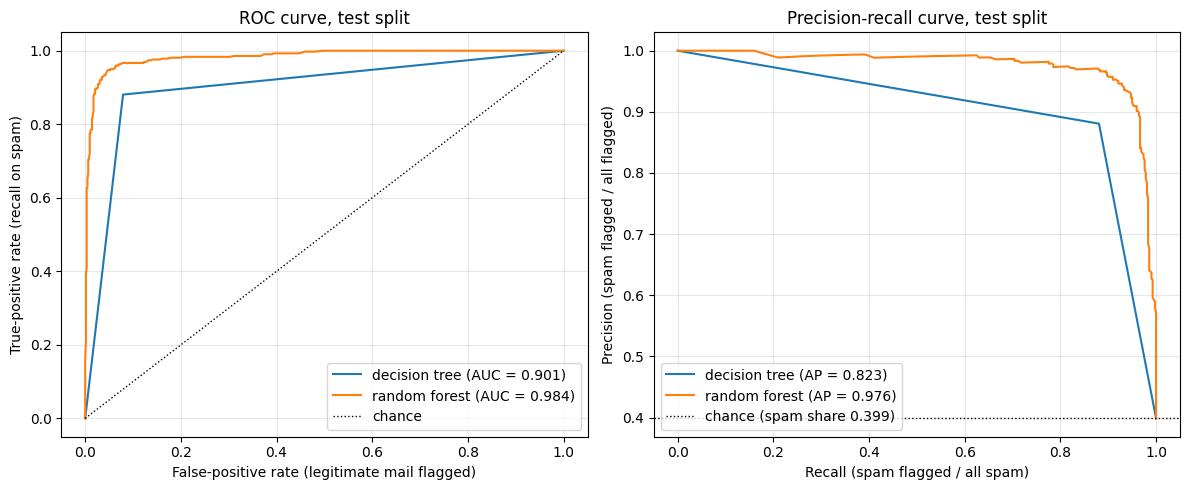

decision tree  ROC AUC = 0.9008   average precision = 0.8232
random forest  ROC AUC = 0.9836   average precision = 0.9760


In [12]:
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_recall_curve, roc_auc_score,
                             roc_curve)

tree_fit = clone(tree).fit(X_train, y_train)
test_scores = {"decision tree": tree_fit.predict_proba(X_test)[:, 1],
               "random forest": rf.predict_proba(X_test)[:, 1]}

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 5))
for name, s in test_scores.items():
    fpr_c, tpr_c, _ = roc_curve(y_test, s)
    prec_c, rec_c, _ = precision_recall_curve(y_test, s)
    ax_roc.plot(fpr_c, tpr_c, label=f"{name} (AUC = {roc_auc_score(y_test, s):.3f})")
    ax_pr.plot(rec_c, prec_c, label=f"{name} (AP = {average_precision_score(y_test, s):.3f})")
ax_roc.plot([0, 1], [0, 1], "k:", lw=1, label="chance")
ax_roc.set(xlabel="False-positive rate (legitimate mail flagged)", ylabel="True-positive rate (recall on spam)",
           title="ROC curve, test split")
ax_pr.axhline(y_test.mean(), color="k", ls=":", lw=1, label=f"chance (spam share {y_test.mean():.3f})")
ax_pr.set(xlabel="Recall (spam flagged / all spam)", ylabel="Precision (spam flagged / all flagged)",
          title="Precision-recall curve, test split")
for ax in (ax_roc, ax_pr):
    ax.legend(loc="lower right" if ax is ax_roc else "lower left")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
for name, s in test_scores.items():
    print(f"{name:14s} ROC AUC = {roc_auc_score(y_test, s):.4f}   average precision = {average_precision_score(y_test, s):.4f}")

### 2.2 A threshold from the training split (out-of-fold probabilities)

In [13]:
from sklearn.model_selection import cross_val_predict

oof = cross_val_predict(rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
fpr_o, tpr_o, thr_o = roc_curve(y_train, oof, drop_intermediate=False)
ok = fpr_o <= 0.01                                     # out-of-fold FPR at most 1 %
best_recall = tpr_o[ok].max()
t = thr_o[ok & (tpr_o == best_recall)].max()           # largest threshold reaching that recall
i_t = np.flatnonzero(thr_o == t)[0]
print(f"t = {t!r}")
print(f"out-of-fold FPR at t    = {fpr_o[i_t]:.4f}  ({round(fpr_o[i_t] * (y_train == 0).sum())} of {(y_train == 0).sum()} legitimate)")
print(f"out-of-fold recall at t = {tpr_o[i_t]:.4f}")
# check directly with the rule "flagged when score >= t"
assert np.isclose(np.mean(oof[y_train == 0] >= t), fpr_o[i_t]) and np.isclose(np.mean(oof[y_train == 1] >= t), tpr_o[i_t])

t = np.float64(0.6766666666666666)
out-of-fold FPR at t    = 0.0090  (17 of 1896 legitimate)
out-of-fold recall at t = 0.8465


### 2.3 Apply it once to the test split

In [14]:
flag = (rf.predict_proba(X_test)[:, 1] >= t).astype(int)
cm = confusion_matrix(y_test, flag, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
display(pd.DataFrame(cm, index=["true: legitimate (0)", "true: spam (1)"],
                     columns=["flagged: legitimate (0)", "flagged: spam (1)"]))
prec_t, rec_t, fpr_t = tp / (tp + fp), tp / (tp + fn), fp / (fp + tn)
print(f"precision = {prec_t:.4f}   recall = {rec_t:.4f}   FPR = {fpr_t:.4f}")
print(f"{fp} of the {fp + tn} legitimate test mails were flagged as spam.")
print(f"SE of the test FPR = {math.sqrt(fpr_t * (1 - fpr_t) / (fp + tn)):.4f}")

,flagged: legitimate (0),flagged: spam (1)
true: legitimate (0),621,11
true: spam (1),56,363


precision = 0.9706   recall = 0.8663   FPR = 0.0174
11 of the 632 legitimate test mails were flagged as spam.
SE of the test FPR = 0.0052


### 2.4 Permutation and impurity importances

In [15]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=SEED, scoring="accuracy")
imp = pd.DataFrame({"permutation (test)": perm.importances_mean,
                    "permutation std": perm.importances_std,
                    "impurity (train)": rf.feature_importances_}, index=feature_names)
imp["rank permutation"] = imp["permutation (test)"].rank(ascending=False, method="min").astype(int)
imp["rank impurity"] = imp["impurity (train)"].rank(ascending=False, method="min").astype(int)
print("Top five by permutation importance:")
display(imp.sort_values("permutation (test)", ascending=False).head(5).round(4))
print("Top five by impurity importance:")
display(imp.sort_values("impurity (train)", ascending=False).head(5).round(4))

Top five by permutation importance:


,permutation (test),permutation std,impurity (train),rank permutation,rank impurity
word_freq_remove,0.0298,0.0028,0.0925,1,3
word_freq_hp,0.0135,0.0030,0.0453,2,9
char_freq_exclam,0.0119,0.0025,0.1025,3,1
char_freq_dollar,0.0094,0.0031,0.0949,4,2
word_freq_free,0.0063,0.0021,0.0630,5,6


Top five by impurity importance:


,permutation (test),permutation std,impurity (train),rank permutation,rank impurity
char_freq_exclam,0.0119,0.0025,0.1025,3,1
char_freq_dollar,0.0094,0.0031,0.0949,4,2
word_freq_remove,0.0298,0.0028,0.0925,1,3
capital_run_length_average,0.0030,0.0024,0.0643,7,4
word_freq_your,-0.0018,0.0017,0.0633,56,5


In [16]:
cols = ["word_freq_your", "capital_run_length_total", "word_freq_hp"]
display(imp.loc[cols].round(4))
corr = data[feature_names].corr().abs()
for c in cols[:2]:
    top = corr[c].drop(c).sort_values(ascending=False).head(3)
    print(c, "is most correlated with:", ", ".join(f"{k} ({v:.2f})" for k, v in top.items()))

,permutation (test),permutation std,impurity (train),rank permutation,rank impurity
word_freq_your,-0.0018,0.0017,0.0633,56,5
capital_run_length_total,-0.0020,0.0017,0.0456,57,8
word_freq_hp,0.0135,0.0030,0.0453,2,9


word_freq_your is most correlated with: word_freq_you (0.30), word_freq_business (0.23), word_freq_receive (0.19)
capital_run_length_total is most correlated with: capital_run_length_longest (0.46), word_freq_order (0.23), char_freq_dollar (0.21)


### Part 2 — answers

**Curves.** On the test split the forest dominates the tree: ROC AUC 0.984 against 0.901 and average precision 0.976
against 0.823. The single tree's curves are almost straight lines because it gives nearly every mail a probability of
0 or 1 (its leaves are pure), so it has essentially one operating point; the forest's averaged votes give a fine-grained
score that can be thresholded.

**Threshold.** On the out-of-fold forest probabilities of the training split, the threshold with the highest recall
among those with FPR ≤ 0.01 is t = 0.6767 (unrounded value printed above). There the out-of-fold FPR is 0.0090
(17 of 1896 legitimate training mails) and the recall is 0.8465.

**Applied once to the test split.** Precision 0.971, recall 0.866, FPR 0.0174: **11 of the 632 legitimate test mails
were flagged as spam.** The 1 % target **did not hold** on the test split: 1.74 % is above 1 % (1 % of 632 would be
at most 6 mails). The threshold was set to sit just below 1 % on the training folds, so it has no margin, and the
test FPR is estimated from only 632 legitimate mails (its standard error is about 0.005), so a test FPR above 1 %
for a threshold set right at the limit is not surprising. Recall (0.866 vs 0.846) carried over well. As the handout
says I do not change t after seeing these numbers; to meet the target more reliably one would choose t on the
training folds for a stricter target (for example 0.5 %), never on the test split.

**Importances.** The two lists share three features (`char_freq_exclam`, `char_freq_dollar`, `word_freq_remove`)
but rank them differently, and two features differ. A clear difference is **`word_freq_your`**: 5th by impurity
importance (0.063) but 56th of 57 by permutation importance (−0.0018, i.e. shuffling it does not hurt test
accuracy at all). The reason is how each is computed. The impurity importance adds up, over all splits in all 300
trees, the drop in Gini impurity on the **training** rows that each feature's splits produce. Because every split
considers only a random subset of features, a common, continuous word like "your" is often the best available
feature and gets used in many splits, collecting credit for every training-set impurity drop even when the same
information is also carried by other features (it is correlated with `word_freq_you` 0.30, `word_freq_business` 0.23,
`word_freq_receive` 0.19, and it overlaps with the stronger spam words). Impurity importance also favours continuous
features with many possible split points, and part of the credit comes from deep splits that only fit training rows. The permutation
importance instead shuffles one column on the **test** split and measures the loss of accuracy of the finished
forest. If other features carry the same signal, the many other trees and splits still classify the mail correctly,
so the drop is near zero. In the other direction, `word_freq_hp` (the "hp" of the donor's employer, a strong sign of
*legitimate* mail) is 2nd by permutation but only 9th by impurity: it is zero for most mails and so takes part in fewer
splits, but the forest relies on it for the mails where it is non-zero and has no substitute for it.

## Part 3 — Voting

In [17]:
def hard_vote(predictions, weights=None):
    """Weighted majority vote of several models' predicted labels, one label per sample.

    predictions: 2-D array-like (n_models, n_samples) of non-negative integer labels; row m = model m.
    weights: None (each model counts 1) or n_models non-negative numbers (not normalised).
    The count of a label is the sum of the weights of the models predicting it, added in model order;
    the label with the largest count wins, ties go to the smallest label (all counts 0 -> label 0).
    Returns a NumPy integer array of shape (n_samples,).
    """
    P = np.array(predictions, dtype=np.int64)          # a copy, the argument is not touched
    if P.ndim != 2:
        P = P.reshape(len(P), -1) if P.size else P.reshape(0, 0)
    n_models, n_samples = P.shape
    w = np.ones(n_models) if weights is None else np.array(weights, dtype=float).reshape(-1)
    if n_models == 0 or n_samples == 0:
        return np.zeros(n_samples, dtype=np.int64)
    counts = np.zeros((int(P.max()) + 1, n_samples))   # one row per label 0..max label
    cols = np.arange(n_samples)
    for m in range(n_models):                          # model 0 first
        counts[P[m], cols] += w[m]
    return np.argmax(counts, axis=0).astype(np.int64)  # argmax takes the first (smallest) label on a tie

In [18]:
assert hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]).tolist() == [0, 1, 0]
assert hard_vote([[0, 1], [1, 0]]).tolist() == [0, 0]
assert hard_vote([[0, 1], [1, 0]], weights=[1, 2]).tolist() == [1, 0]
assert hard_vote([[2, 0], [2, 1], [0, 1]]).tolist() == [2, 1]
assert hard_vote([[0, 1], [1, 0]], weights=[0, 0]).tolist() == [0, 0]               # all counts 0 -> 0
assert hard_vote(np.array([[3, 3], [1, 2]]), weights=[1, 1]).tolist() == [1, 2]     # tie -> smallest label
_p, _w = [[0, 1], [1, 0]], [1, 2]; hard_vote(_p, _w); assert _p == [[0, 1], [1, 0]] and _w == [1, 2]
assert hard_vote([[0, 1]]).dtype.kind == "i"
print("hard_vote: all examples pass")

hard_vote: all examples pass


### 3.1 Reproduce scikit-learn

In [19]:
from sklearn.ensemble import VotingClassifier

fitted = {name: clone(m).fit(X_train, y_train) for name, m in members}
member_pred = np.vstack([fitted[name].predict(X_test) for name, _ in members])     # shape (3, n_test)
mine = hard_vote(member_pred)
sk_hard = VotingClassifier(members, voting="hard").fit(X_train, y_train).predict(X_test)
print("shape of the prediction matrix:", member_pred.shape)
print(f"fraction of test rows where hard_vote and VotingClassifier(voting='hard') agree: {np.mean(mine == sk_hard):.4f}")

shape of the prediction matrix: (3, 1051)
fraction of test rows where hard_vote and VotingClassifier(voting='hard') agree: 1.0000
